# 09 — Validation des soudures : profil ISO 2560-A E 42 2, k = 2

Seuils et règle définis dans
[reports/18_seuils_validation_fr.md](../reports/18_seuils_validation_fr.md),
choix confirmés par l'utilisateur le 12 octobre 2026 : profil **P2**, bande de
garde **k = 2**. Préférences recommandées par le rapport et appliquées : borne
haute d'UTS informative (non critique), toutes les bornes basses critiques,
« partiel » = indéterminé.

| Critère | Cible (unité) | Seuil | Critique |
| --- | --- | --- | --- |
| `ys_min` | YS (MPa) | ≥ 420 | oui |
| `uts_min` | UTS (MPa) | ≥ 500 | oui |
| `uts_max` | UTS (MPa) | ≤ 640 | non |
| `el_min` | allongement (%) | ≥ 20 | oui |
| `kv_min` | Charpy KV (J) à −20 °C | ≥ 47 | oui |

Statut par critère (JCGM 106 §8.3), w = k·u : **C** si la valeur dépasse le
seuil de plus de w du bon côté, **NC** si elle est au-delà de w du mauvais
côté, **I** sinon ou si la valeur manque. Décision : **VALIDÉ** si tous les
critères sont C, **NON VALIDÉ** si un critère critique est NC, **PARTIEL** sinon.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import platform

import numpy as np
import pandas as pd

TARGETS = ['yield_strength', 'uts', 'elongation', 'charpy_J']
PROTOCOLS = ['random', 'grouped']
K = 2.0
C, I, NC = 'C', 'I', 'NC'
VALIDE, PARTIEL, NON_VALIDE = 'VALIDÉ', 'PARTIEL', 'NON VALIDÉ'
DECISIONS = [VALIDE, PARTIEL, NON_VALIDE]

# Profil P2 du rapport 18 : YS/UTS en MPa, allongement en %, KV en J à la température du profil (°C).
PROFILE = {
    'name': 'ISO 2560-A E 42 2',
    'charpy_temp_C': -20.0,
    'criteria': [
        {'id': 'ys_min', 'target': 'yield_strength', 'kind': 'min', 'limit': 420.0, 'critical': True},
        {'id': 'uts_min', 'target': 'uts', 'kind': 'min', 'limit': 500.0, 'critical': True},
        {'id': 'uts_max', 'target': 'uts', 'kind': 'max', 'limit': 640.0, 'critical': False},
        {'id': 'el_min', 'target': 'elongation', 'kind': 'min', 'limit': 20.0, 'critical': True},
        {'id': 'kv_min', 'target': 'charpy_J', 'kind': 'min', 'limit': 47.0, 'critical': True},
    ],
}
CRITERIA = [c['id'] for c in PROFILE['criteria']]


def criterion_status(value, limit, kind, w):
    """Statut gardé (JCGM 106 §8.3) : C hors de la bande côté conforme, NC hors de la bande
    côté non conforme, I dans la bande ou si la valeur manque. Les limites d'acceptation
    appartiennent à l'intervalle d'acceptation."""
    value = np.asarray(value, dtype=float)
    w = np.broadcast_to(np.asarray(w, dtype=float), value.shape)
    if np.any(w < 0):
        raise ValueError('la bande de garde doit être positive ou nulle')
    if kind == 'min':
        ok, bad = value - w >= limit, value + w < limit
    elif kind == 'max':
        ok, bad = value + w <= limit, value - w > limit
    else:
        raise ValueError(f'type de borne inconnu : {kind}')
    status = np.where(ok, C, np.where(bad, NC, I)).astype(object)
    status[np.isnan(value)] = I
    return status


def charpy_measured_status(temp, energy, t_req, e_min):
    """Un seul couple E(T) mesuré par ligne. L'énergie est supposée croissante avec T dans
    la transition : E(T) >= e_min avec T <= t_req prouve la conformité, E(T) < e_min avec
    T >= t_req prouve la non-conformité, les autres couples ne tranchent pas."""
    temp = np.asarray(temp, dtype=float)
    energy = np.asarray(energy, dtype=float)
    ok = (temp <= t_req) & (energy >= e_min)
    bad = (temp >= t_req) & (energy < e_min)
    status = np.where(ok, C, np.where(bad, NC, I)).astype(object)
    status[np.isnan(temp) | np.isnan(energy)] = I
    return status


def aggregate(statuses, profile=PROFILE):
    """VALIDÉ si tous les critères sont C ; NON VALIDÉ si un critère critique est NC ; PARTIEL sinon."""
    ids = [c['id'] for c in profile['criteria']]
    critical = [c['id'] for c in profile['criteria'] if c['critical']]
    all_c = statuses[ids].eq(C).all(axis=1)
    critical_nc = statuses[critical].eq(NC).any(axis=1)
    decision = np.where(all_c, VALIDE, np.where(critical_nc, NON_VALIDE, PARTIEL))
    return pd.Series(decision, index=statuses.index, name='decision')


def validate_predictions(values, rmse, profile=PROFILE, k=K):
    """values : une colonne par cible, KV prédit à la température du profil ;
    rmse : incertitude u par cible, dans l'unité de la cible."""
    out = pd.DataFrame(index=values.index)
    for c in profile['criteria']:
        out[c['id']] = criterion_status(values[c['target']], c['limit'], c['kind'], k * rmse[c['target']])
    out['decision'] = aggregate(out, profile)
    return out


def validate_measurements(frame, profile=PROFILE):
    """Mesures de la base, sans incertitude publiée : acceptation simple (w = 0) ;
    KV par la règle monotone sur le couple (charpy_temp_C, charpy_J)."""
    out = pd.DataFrame(index=frame.index)
    for c in profile['criteria']:
        if c['target'] == 'charpy_J':
            out[c['id']] = charpy_measured_status(frame.charpy_temp_C, frame.charpy_J,
                                                  profile['charpy_temp_C'], c['limit'])
        else:
            out[c['id']] = criterion_status(frame[c['target']], c['limit'], c['kind'], 0.0)
    out['decision'] = aggregate(out, profile)
    return out

In [2]:
def pooled_rmse(predictions):
    """RMSE hors pli réunie (toutes les validations externes) par protocole et cible."""
    error = predictions.y_true - predictions.y_pred
    return error.pow(2).groupby([predictions.protocol, predictions.target]).mean().pow(0.5)


def prediction_folds(raw_ids, protocol, target, random_assign, grouped_assign, labeled):
    """Pli externe dont le modèle n'a jamais vu la ligne.

    Groupé : pli de la série, commun aux cibles. Aléatoire : pli propre à la cible.
    Une ligne sans label Charpy n'a pas de pli Charpy ; aucun modèle Charpy ne l'a vue,
    le pli YS de la même ligne est repris pour choisir un des cinq modèles.
    """
    raw_ids = pd.Index(raw_ids, name='raw_row_id')
    labeled = np.asarray(labeled, dtype=bool)
    if protocol == 'grouped':
        folds = grouped_assign.set_index('raw_row_id').outer_fold.reindex(raw_ids)
    elif protocol == 'random':
        by_target = random_assign.loc[random_assign.target == target].set_index('raw_row_id').outer_fold
        folds = by_target.reindex(raw_ids)
        if np.any(folds.isna().to_numpy() & labeled):
            raise ValueError('ligne labellisée sans pli pour sa cible')
        fallback = random_assign.loc[random_assign.target == 'yield_strength'].set_index('raw_row_id').outer_fold
        folds = folds.fillna(fallback.reindex(raw_ids))
    else:
        raise ValueError(f'protocole inconnu : {protocol}')
    if folds.isna().any():
        raise ValueError('ligne sans pli externe')
    return folds.astype(int)


def predict_out_of_fold(frame, folds, load_model, charpy_temp_C=None):
    """Prédit chaque ligne avec le modèle de son pli. charpy_temp_C remplace la
    température d'essai pour évaluer KV à la température requise par le profil."""
    prediction = pd.Series(np.nan, index=frame.index, dtype=float)
    for fold in sorted(folds.unique()):
        model, features = load_model(fold)
        rows = folds.index[folds == fold]
        X = frame.loc[rows, features].copy()
        if charpy_temp_C is not None:
            if 'charpy_temp_C' not in features:
                raise ValueError('modèle sans température Charpy en entrée')
            X['charpy_temp_C'] = float(charpy_temp_C)
        prediction.loc[rows] = model.predict(X)
    return prediction


def compare_statuses(predicted, measured, columns):
    """Confronte statut prédit et statut mesuré, seulement là où la mesure tranche."""
    rows = []
    for column in columns:
        decided = measured[column].isin([C, NC])
        table = pd.crosstab(measured.loc[decided, column], predicted.loc[decided, column])
        count = lambda m, p: int(table.at[m, p]) if m in table.index and p in table.columns else 0
        accepted = count(C, C) + count(NC, C)
        rejected = count(C, NC) + count(NC, NC)
        rows.append({
            'criterion': column, 'n_measure_decided': int(decided.sum()),
            'measure_C': int((measured.loc[decided, column] == C).sum()),
            'measure_NC': int((measured.loc[decided, column] == NC).sum()),
            'pred_C_measure_C': count(C, C), 'pred_C_measure_NC': count(NC, C),
            'pred_NC_measure_C': count(C, NC), 'pred_NC_measure_NC': count(NC, NC),
            'pred_I': count(C, I) + count(NC, I),
            'false_acceptance_share': count(NC, C) / accepted if accepted else np.nan,
            'false_rejection_share': count(C, NC) / rejected if rejected else np.nan,
        })
    return pd.DataFrame(rows)

## Données, plis et modèles

Population : cohorte strict13 (1 555 lignes, 44 séries), domaine d'entrée des
modèles. Les 93 lignes hors cohorte ont plus de deux entrées A1_13 manquantes et
ne sont pas prédites. Unités du master : compositions en % massique, O/N en ppm,
températures en °C ; cibles en MPa, %, J. `N` reste manquant, jamais zéro.

Modèles : procédure supervisée **à six familles avec sélection par MAE
interne** (`models/salh_xgboost_v1/<protocole>/outer_selected/`, notebook 08),
la référence courante depuis l'ajout de XGBoost. Chaque ligne est prédite par
le modèle externe qui ne l'a pas vue (ni sa série en groupé). Les refits
complets de `selected_models.json` ont vu tous les labels : ils ne sont pas
utilisés pour cette évaluation. L'incertitude u est la RMSE hors pli réunie
de cette même procédure, par protocole et cible.

In [3]:
import cloudpickle

PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'sujet.md').is_file())
DATA = PROJECT_ROOT / 'data/processed/modeling'
SOURCE = PROJECT_ROOT / 'data/processed/experiments/salh_xgboost_v1'
MODELS = PROJECT_ROOT / 'models/salh_xgboost_v1'
OUT = PROJECT_ROOT / 'data/processed/experiments/salh_validation_v1'
FIGURE = PROJECT_ROOT / 'reports/figures/18_validation_decisions_fr.png'
OUT.mkdir(parents=True, exist_ok=True)


def sha256(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()


master = pd.read_csv(DATA / 'master.csv', low_memory=False)
cohort = master.loc[~master.is_duplicate_excess & master.in_strict13].set_index('raw_row_id', drop=False)
random_assign = pd.read_csv(SOURCE / 'random_fold_assignments.csv')
grouped_assign = pd.read_csv(SOURCE / 'grouped_fold_assignments.csv')
oof = pd.read_csv(SOURCE / 'inner_selected_predictions.csv')
assert len(cohort) == 1555 and cohort.group.nunique() == 44
assert set(oof.protocol) == set(PROTOCOLS) and set(oof.target) == set(TARGETS)

rmse = pooled_rmse(oof)
rmse_table = rmse.rename('rmse').reset_index().assign(
    k=K, w=lambda d: K * d.rmse,
    n_oof=lambda d: [int(((oof.protocol == p) & (oof.target == t)).sum()) for p, t in zip(d.protocol, d.target)])
display(rmse_table)

model_records = []


def model_loader(protocol, target):
    def load(fold):
        fold = int(fold)
        path = MODELS / protocol / 'outer_selected' / f'{target}_fold{fold}.pkl'
        meta = json.loads(path.with_suffix('.json').read_text())
        assert sha256(path) == meta['artifact_sha256']
        assert (meta['protocol'], meta['target'], meta['outer_fold']) == (protocol, target, fold)
        with path.open('rb') as stream:
            model = cloudpickle.load(stream)
        model_records.append({'protocol': protocol, 'target': target, 'outer_fold': fold,
                              'family': meta['family'], 'path': str(path.relative_to(PROJECT_ROOT)),
                              'sha256': meta['artifact_sha256'],
                              'train_raw_row_ids': set(meta['train_raw_row_ids']),
                              'train_groups': set(meta['train_groups'])})
        return model, meta['features']
    return load

,protocol,target,rmse,k,w,n_oof
0,grouped,charpy_J,47.982284,2.0,95.964567,861
1,grouped,elongation,4.145720,2.0,8.291439,631
2,grouped,uts,70.724631,2.0,141.449262,677
3,grouped,yield_strength,72.248183,2.0,144.496365,706
4,random,charpy_J,19.744350,2.0,39.488701,861
5,random,elongation,2.907004,2.0,5.814008,631
6,random,uts,36.623369,2.0,73.246738,677
7,random,yield_strength,39.568142,2.0,79.136284,706


In [4]:
predictions = {}
fold_used = {}
for protocol in PROTOCOLS:
    values = pd.DataFrame(index=cohort.index)
    for target in TARGETS:
        folds = prediction_folds(cohort.index, protocol, target, random_assign, grouped_assign,
                                 labeled=cohort[target].notna())
        fold_used[(protocol, target)] = folds
        load = model_loader(protocol, target)
        # Contrôle : aux entrées observées, les lignes labellisées reproduisent les OOF exportés.
        labeled = cohort.loc[cohort[target].notna()]
        reproduced = predict_out_of_fold(labeled, folds.loc[labeled.index], load)
        reference = oof.loc[(oof.protocol == protocol) & (oof.target == target)].set_index('raw_row_id').y_pred
        assert set(reference.index) == set(labeled.index)
        np.testing.assert_allclose(reproduced.loc[reference.index], reference, rtol=1e-6, atol=1e-6)
        temp = PROFILE['charpy_temp_C'] if target == 'charpy_J' else None
        values[target] = predict_out_of_fold(cohort, folds, load, charpy_temp_C=temp)
    predictions[protocol] = values
    assert values.notna().all().all()

# Aucun modèle n'a vu la ligne qu'il prédit ; en groupé, ni sa série.
for record in model_records:
    rows = fold_used[(record['protocol'], record['target'])]
    rows = rows.index[rows == record['outer_fold']]
    assert not set(rows) & record['train_raw_row_ids']
    if record['protocol'] == 'grouped':
        assert not set(cohort.loc[rows, 'group']) & record['train_groups']
print(len(model_records), 'chargements vérifiés')

80 chargements vérifiés


## Statuts : mesures et modèles

Mesures : acceptation simple (w = 0), aucune incertitude de mesure n'étant
publiée dans la base. Une cible absente donne I. KV mesuré n'est tranché que
par la règle monotone sur l'unique couple E(T) de la ligne ; les couples codés
28 J / 100 J sont lus comme des mesures E(T), sans reclassement.

Modèles : KV est prédit à **−20 °C** pour toutes les lignes, y compris celles
sans essai Charpy. La RMSE Charpy est estimée aux températures d'essai observées
et appliquée à −20 °C : c'est une approximation.

In [5]:
SOURCES = {'mesures': 'Mesures', 'random': 'Modèle KFold aléatoire', 'grouped': 'Modèle GroupKFold'}
status = {'mesures': validate_measurements(cohort)}
for protocol in PROTOCOLS:
    u = rmse.loc[protocol].to_dict()
    status[protocol] = validate_predictions(predictions[protocol], u)

decision_summary = pd.DataFrame({
    source: status[source].decision.value_counts().reindex(DECISIONS, fill_value=0)
    for source in SOURCES}).T
decision_share = decision_summary.div(decision_summary.sum(axis=1), axis=0).mul(100).round(1)
display(decision_summary, decision_share)

criterion_summary = pd.concat({
    source: status[source][CRITERIA].apply(lambda s: s.value_counts().reindex([C, I, NC], fill_value=0))
    for source in SOURCES}).rename_axis(['source', 'status'])
display(criterion_summary)

decision,VALIDÉ,PARTIEL,NON VALIDÉ
mesures,51,1274,230
random,0,1538,17
grouped,0,1555,0


decision,VALIDÉ,PARTIEL,NON VALIDÉ
mesures,3.3,81.9,14.8
random,0.0,98.9,1.1
grouped,0.0,100.0,0.0


ys_min  uts_min  uts_max  el_min  kv_min
source  status                                          
mesures C          597      594      495     559     421
        I          849      878      878     924    1090
        NC         109       83      182      72      44
random  C          723      808      711     895    1186
        I          828      747      660     651     365
        NC           4        0      184       9       4
grouped C          280      375       65     460      60
        I         1275     1180     1453    1095    1495
        NC           0        0       37       0       0

## Accord entre décisions prédites et mesures

Sur les lignes où la mesure tranche (C ou NC), part des acceptations prédites
contredites par la mesure (fausses acceptations) et des rejets prédits
contredits (faux rejets). Avec k = 2 et des erreurs normales homogènes, la
fausse acceptation d'un critère est au plus de 2,3 % pour une valeur prédite à
la limite d'acceptation (JCGM 106 §8.3.2.3).

In [6]:
agreement = pd.concat([
    compare_statuses(status[protocol], status['mesures'], CRITERIA).assign(protocol=protocol)
    for protocol in PROTOCOLS], ignore_index=True)
display(agreement)

decision_cross = {
    protocol: pd.crosstab(status['mesures'].decision, status[protocol].decision).reindex(
        index=DECISIONS, columns=DECISIONS, fill_value=0)
    for protocol in PROTOCOLS}
for protocol, table in decision_cross.items():
    print(SOURCES[protocol], '(lignes : décision mesurée ; colonnes : décision prédite)')
    display(table)

# Sensibilités, sans changer la règle retenue : borne haute d'UTS critique (classification
# ISO stricte) ou ignorée (seules les bornes basses décident).
VARIANTS = {
    'uts_max_critique': {**PROFILE, 'criteria': [{**c, 'critical': True} for c in PROFILE['criteria']]},
    'uts_max_ignoree': {**PROFILE, 'criteria': [c for c in PROFILE['criteria'] if c['id'] != 'uts_max']},
}
variant_decisions = {(v, s): aggregate(status[s][CRITERIA], profile)
                     for v, profile in VARIANTS.items() for s in SOURCES}
sensitivity_summary = pd.DataFrame({key: d.value_counts().reindex(DECISIONS, fill_value=0)
                                    for key, d in variant_decisions.items()}).T.rename_axis(['variant', 'source'])
display(sensitivity_summary)
sensitivity_cross = {
    (v, p): pd.crosstab(variant_decisions[(v, 'mesures')], variant_decisions[(v, p)]).reindex(
        index=DECISIONS, columns=DECISIONS, fill_value=0)
    for v in VARIANTS for p in PROTOCOLS}
display(sensitivity_cross[('uts_max_ignoree', 'random')])

,criterion,n_measure_decided,measure_C,measure_NC,pred_C_measure_C,pred_C_measure_NC,pred_NC_measure_C,pred_NC_measure_NC,pred_I,false_acceptance_share,false_rejection_share,protocol
0,ys_min,706,597,109,351,2,0,4,349,0.005666,0.000000,random
1,uts_min,677,594,83,350,0,0,0,327,0.000000,NaN,random
2,uts_max,677,495,182,303,4,1,69,300,0.013029,0.014286,random
3,el_min,631,559,72,371,5,0,0,255,0.013298,NaN,random
4,kv_min,465,421,44,398,1,0,1,65,0.002506,0.000000,random
5,ys_min,706,597,109,110,2,0,0,594,0.017857,NaN,grouped
6,uts_min,677,594,83,130,0,0,0,547,0.000000,NaN,grouped
7,uts_max,677,495,182,42,1,3,18,613,0.023256,0.142857,grouped
8,el_min,631,559,72,172,1,0,0,458,0.005780,NaN,grouped
9,kv_min,465,421,44,34,0,0,0,431,0.000000,NaN,grouped


Modèle KFold aléatoire (lignes : décision mesurée ; colonnes : décision prédite)


decision,VALIDÉ,PARTIEL,NON VALIDÉ
decision,,,
VALIDÉ,0,51,0
PARTIEL,0,1264,10
NON VALIDÉ,0,223,7


Modèle GroupKFold (lignes : décision mesurée ; colonnes : décision prédite)


decision,VALIDÉ,PARTIEL,NON VALIDÉ
decision,,,
VALIDÉ,0,51,0
PARTIEL,0,1274,0
NON VALIDÉ,0,230,0


decision                  VALIDÉ  PARTIEL  NON VALIDÉ
variant          source                              
uts_max_critique mesures      51     1156         348
                 random        0     1356         199
                 grouped       0     1518          37
uts_max_ignoree  mesures      58     1267         230
                 random      125     1413          17
                 grouped       0     1555           0

decision,VALIDÉ,PARTIEL,NON VALIDÉ
decision,,,
VALIDÉ,5,53,0
PARTIEL,118,1139,10
NON VALIDÉ,2,221,7


## Figure, exports et manifeste

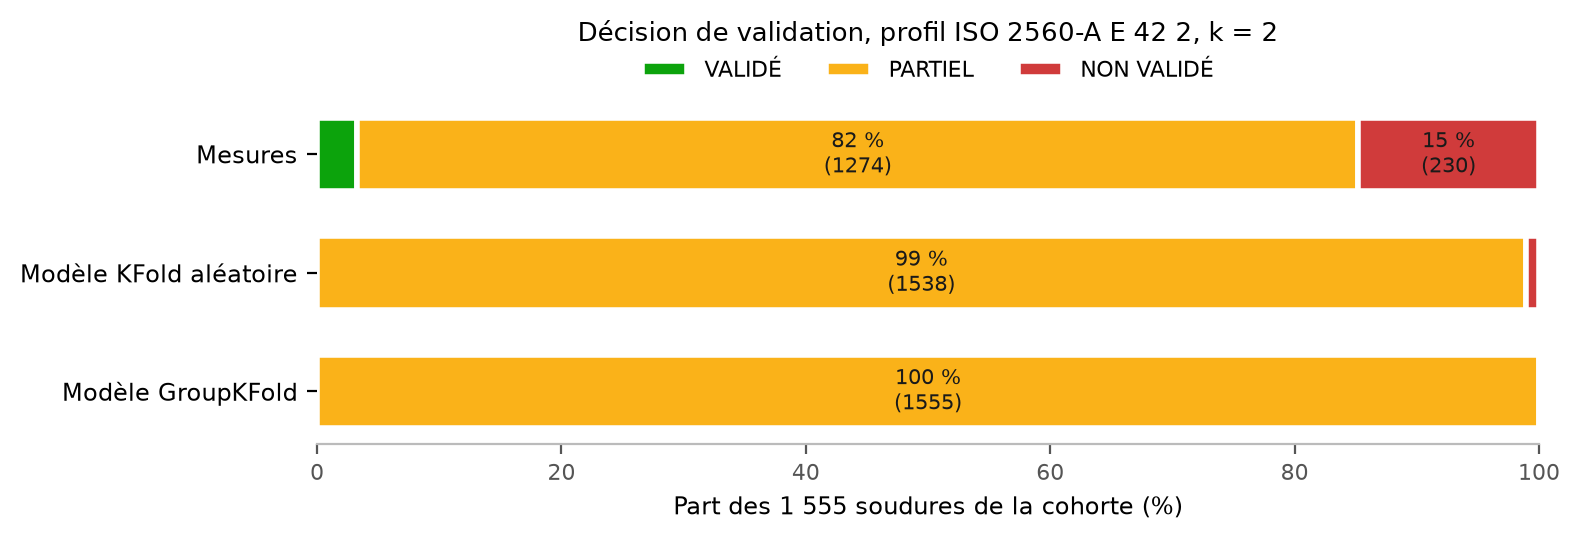

exports : ['agreement.csv', 'criterion_summary.csv', 'decision_cross.csv', 'decision_summary.csv', 'rmse_used.csv', 'row_status.csv', 'sensitivity_cross.csv', 'sensitivity_summary.csv']


In [7]:
import matplotlib.pyplot as plt

# Couleurs de statut réservées (bon, attention, critique), toujours doublées d'une étiquette.
STATUS_COLORS = {VALIDE: '#0ca30c', PARTIEL: '#fab219', NON_VALIDE: '#d03b3b'}
order = list(SOURCES)[::-1]
fig, ax = plt.subplots(figsize=(8, 2.8), dpi=200)
left = np.zeros(len(order))
for decision in DECISIONS:
    share = decision_share.loc[order, decision].to_numpy()
    counts = decision_summary.loc[order, decision].to_numpy()
    ax.barh(range(len(order)), share, left=left, height=0.62, color=STATUS_COLORS[decision],
            edgecolor='white', linewidth=2, label=decision)
    for y, (x0, s, n) in enumerate(zip(left, share, counts)):
        if s >= 6:
            ax.text(x0 + s / 2, y, f'{s:.0f} %\n({n})', ha='center', va='center', fontsize=7.5, color='#1a1a19')
    left += share
ax.set_yticks(range(len(order)), [SOURCES[s] for s in order], fontsize=8.5)
ax.set_xlim(0, 100)
ax.set_xlabel('Part des 1 555 soudures de la cohorte (%)', fontsize=8.5)
ax.tick_params(axis='x', labelsize=8, colors='#555')
for side in ['top', 'right', 'left']:
    ax.spines[side].set_visible(False)
ax.spines['bottom'].set_color('#bbb')
ax.legend(ncol=3, frameon=False, fontsize=8, loc='lower center', bbox_to_anchor=(0.5, 1.0))
ax.set_title('Décision de validation, profil ISO 2560-A E 42 2, k = 2', fontsize=9.5, pad=22)
fig.tight_layout()
fig.savefig(FIGURE, bbox_inches='tight')
plt.show()

rows = []
for source in SOURCES:
    frame = status[source].add_prefix('status_').rename(columns={'status_decision': 'decision'})
    values = cohort[TARGETS] if source == 'mesures' else predictions[source]
    frame = pd.concat([cohort[['raw_row_id', 'group']], values.add_prefix('value_'), frame], axis=1)
    if source == 'mesures':
        frame['value_charpy_temp_C'] = cohort.charpy_temp_C
    else:
        frame['value_charpy_temp_C'] = PROFILE['charpy_temp_C']
    rows.append(frame.assign(source=source))
row_status = pd.concat(rows, ignore_index=True)
assert len(row_status) == 3 * len(cohort)

exports = {
    'rmse_used.csv': rmse_table,
    'row_status.csv': row_status,
    'decision_summary.csv': decision_summary.rename_axis('source').reset_index(),
    'criterion_summary.csv': criterion_summary.reset_index(),
    'agreement.csv': agreement,
    'decision_cross.csv': pd.concat(decision_cross, names=['protocol', 'measured_decision']).reset_index(),
    'sensitivity_summary.csv': sensitivity_summary.reset_index(),
    'sensitivity_cross.csv': pd.concat(sensitivity_cross, names=['variant', 'protocol', 'measured_decision']).reset_index(),
}
for name, table in exports.items():
    table.to_csv(OUT / name, index=False)

import sklearn, xgboost
manifest = {
    'created_utc': datetime.now(timezone.utc).isoformat(timespec='seconds'),
    'notebook': 'notebooks/09_validation.ipynb',
    'profile': PROFILE, 'k': K,
    'uncertainty': 'RMSE hors pli réunie de la sélection interne à six familles (notebook 08)',
    'population': {'rows': len(cohort), 'groups': int(cohort.group.nunique()), 'filter': 'in_strict13 & ~is_duplicate_excess'},
    'inputs': {str(p.relative_to(PROJECT_ROOT)): sha256(p) for p in [
        DATA / 'master.csv', SOURCE / 'random_fold_assignments.csv',
        SOURCE / 'grouped_fold_assignments.csv', SOURCE / 'inner_selected_predictions.csv']},
    'models': list({r['path']: {k: v for k, v in r.items() if k not in ('train_raw_row_ids', 'train_groups')}
                    for r in model_records}.values()),
    'outputs': {name: sha256(OUT / name) for name in exports} | {str(FIGURE.relative_to(PROJECT_ROOT)): sha256(FIGURE)},
    'versions': {'python': platform.python_version(), 'numpy': np.__version__, 'pandas': pd.__version__,
                 'sklearn': sklearn.__version__, 'xgboost': xgboost.__version__},
}
(OUT / 'manifest.json').write_text(json.dumps(manifest, indent=2, ensure_ascii=False))
print('exports :', sorted(exports))

## Interprétation

Résultats chiffrés, lecture et limites :
[reports/18_seuils_validation_fr.md](../reports/18_seuils_validation_fr.md),
section 7. Les décisions des modèles sont des aides au tri : un PARTIEL
demande un essai réel, et la règle n'a pas été confirmée sur un jeu indépendant.